In [1]:
%load_ext autoreload
%autoreload 2

from nntool.api import NNGraph
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
# import matplotlib.patches as patches
# %matplotlib widget
# import logging
# logging.basicConfig(level=logging.ERROR)
import pickle
import cv2
import torch
import os
import copy

import sys
sys.path.append("../../../yolox_people_detection/quantization")
from dataset_generators import CostomCOCODaset, get_annotations
sys.path.append("../../../yolox_people_detection")
from decoding_layer.decoding import decode_C_style

sys.path.append("../../../YOLOX")
from yolox.data.data_augment import preproc as preprocess
from yolox.utils import multiclass_nms, demo_postprocess, vis

In [2]:
class YOLOXCOCODaset(CostomCOCODaset):
    def __init__(
        self, 
        image_folder, 
        annotations, 
        input_size,
        max_size=500, 
        transpose_to_chw=True,
        input_channels=3,
        img_type = "rgb",
        enable_slicing=True
        ):

        self._img = None
        self._ratio = 1
        super().__init__(
            image_folder, annotations, input_size, max_size, transpose_to_chw,
            input_channels, img_type, enable_slicing
        )

    def __iter__(self):
        self._idx = 0
        return self

    def __next__(self):

        if self._idx >= self.max_idx:
            raise StopIteration()

        filename = self.annotations[self._idx]["file_name"]

        if self.img_type == "bayer":
            filename = filename.replace("jpg", "png")
        img_file = os.path.join(self.data_dir, filename)

        # read image as BGR
        image = cv2.imread(
            img_file,
            cv2.IMREAD_UNCHANGED
        )
        if image is None:
            img_file = img_file.replace(".jpg", ".ppm").replace(".jpeg", ".ppm")
            image = cv2.imread(
                img_file,
                cv2.IMREAD_UNCHANGED
            )

        if self.transpose_to_chw:
            swap = (2, 0, 1)
        else:
            swap = (0, 1, 2)

        self._img = image
        processed_img, self._ratio = preprocess(image.copy(), self.input_size, swap)

        self._idx += 1
        return processed_img[None] 
    
    def __len__(self):
        return self.max_idx

In [3]:
def post_process(model_out, ratio, input_shape, score_thr=0.11, mul_scores=True, add=False):
    predictions = demo_postprocess(model_out[0].copy()[None, :], input_shape)[0]

    boxes = predictions[:, :4]
    
    if add:
        predictions[:, 4] += predictions[:, 4].min()
    if mul_scores:
        scores = predictions[:, 4:5] * predictions[:, 5:]
    else:
        scores = predictions[:, 5:]
        # scores = predictions[:, 4:5]

    boxes_xyxy = np.ones_like(boxes)
    boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
    boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
    boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
    boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
    boxes_xyxy /= ratio
    dets = multiclass_nms(boxes_xyxy, scores, nms_thr=0.45, score_thr=score_thr)
    return dets

In [4]:
def clip_stats(stats, n_std):
    clipped_stats = copy.deepcopy(stats)
    if n_std:
        for layer, stat in stats.items():
            min_, max_ = stat['range_out'][0]['min'], stat['range_out'][0]['max']
            mean, std = stat['range_out'][0]['mean'], stat['range_out'][0]['std']
            clipped_stats[layer]['range_out'][0]['min'] = max(min_, mean - n_std * std)
            clipped_stats[layer]['range_out'][0]['max'] = min(max_, mean + n_std * std)
    return clipped_stats

In [5]:
G = NNGraph.load_graph("../../../YOLOX_outputs/pg_coco_192_full_exp_8_bee_working/best_ckpt_d.onnx", load_quantization=False)
max_activ_size, total_params = G.total_memory_usage
ops = G.total_ops

print(f"{G.name}:")
print(f"\tMax Active Size:\t{max_activ_size} elements")
print(f"\tTotal # Parameters:\t{total_params} elements")
print(f"\tTotal # Operations:\t{ops / 1e6:.2f} MOps")

## fix the order of the last layer to match that in pytorch 
G[-1].fixed_order = True

G.adjust_order()
G.add_dimensions()
G.fusions('scaled_match_group')
G.fusions('expression_matcher')

only align_corners is supported as coordinate_transformation_mode not asymmetric
_backbone_upsample_Resize - only round_prefer_ceil is supported for nearest mode not floor
only align_corners is supported as coordinate_transformation_mode not asymmetric
_backbone_upsample_1_Resize - only round_prefer_ceil is supported for nearest mode not floor


best_ckpt_d:
	Max Active Size:	589824 elements
	Total # Parameters:	889058 elements
	Total # Operations:	150.09 MOps


In [6]:
# calculate statistics
annotations = get_annotations("../../../YOLOX/datasets/pg_coco/annotations/instances_bee_working.json")
# quant_dataset = CostomCOCODaset(
#     image_folder     = "../../../YOLOX/datasets/pg_coco/val2017",
#     annotations      = annotations,
#     max_size         = 1000,
#     input_size       = (192, 256),
#     transpose_to_chw = True,
#     input_channels   = 3,
#     img_type         = "rgb",
#     enable_slicing   = False
# )
quant_dataset = YOLOXCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/bee_working",
    annotations      = annotations,
    max_size         = 250,
    input_size       = (192, 256),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = False
)
sample = next(quant_dataset)
sample.shape

Loading annotations for class person...
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


(1, 3, 192, 256)

In [8]:
float_execution = G.execute(sample, quantize=False)

In [9]:
float_out = [float_execution[out_node.step_idx][0] for out_node in G.outputs()]

In [10]:
float_out[0].shape

(1008, 6)

In [11]:
float_predictions = demo_postprocess(float_out[0].copy()[None, :], (192, 256))[0]
float_predictions[:3]

array([[7.0566730e+00, 5.6191564e+00, 4.0783801e+00, 4.6713476e+00,
        5.9812667e-04, 1.5813661e-01],
       [1.7556946e+01, 5.9789634e+00, 4.8220997e+00, 4.7595253e+00,
        7.5293117e-04, 4.5421541e-01],
       [2.2395199e+01, 3.9843802e+00, 6.4867034e+00, 5.5395212e+00,
        3.1452674e-02, 4.9367258e-01]], dtype=float32)

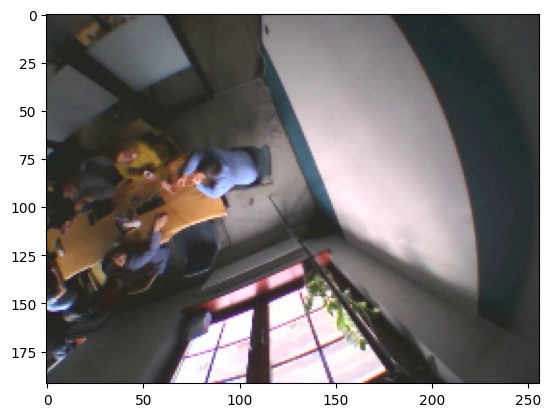

In [12]:
img = cv2.cvtColor(np.transpose(sample[0].copy(), (1, 2, 0)).astype(np.uint8), cv2.COLOR_BGR2RGB)
plt.imshow(img)

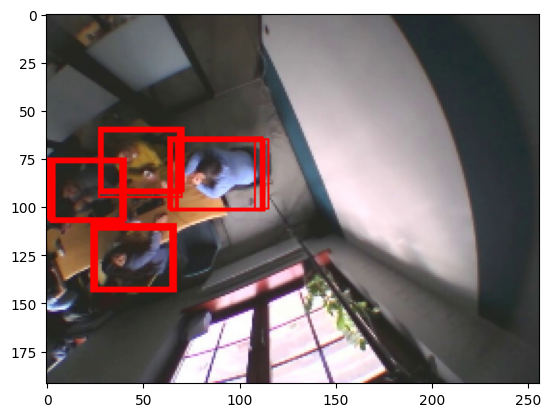

In [13]:
scores = float_predictions[:, -1] * float_predictions[:, -2]

boxes = float_predictions[scores > 0.1][:, :4].copy()
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)

tmp = img.copy()
for box in boxes_xyxy:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

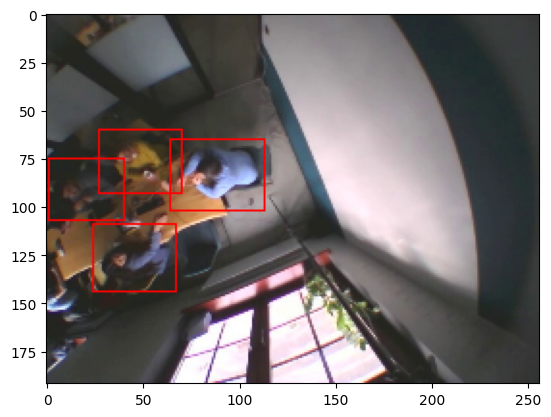

In [14]:
dets = post_process(float_out, 1, (192, 256))
tmp = img.copy()
for box in dets[:,:4].astype(int):
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

In [15]:
flout = G.execute(sample)

onode = G["output_1"]

float_boxes = flout[onode.step_idx][0]
strides = [8, 16, 32]
feature_map_sizes = [(24, 32), (12, 16), (6, 8)]
decoded_float_boxes = decode_C_style(float_boxes.flatten(), feature_map_sizes, strides)

In [16]:
decoded_float_boxes = decoded_float_boxes.reshape(-1, 6)

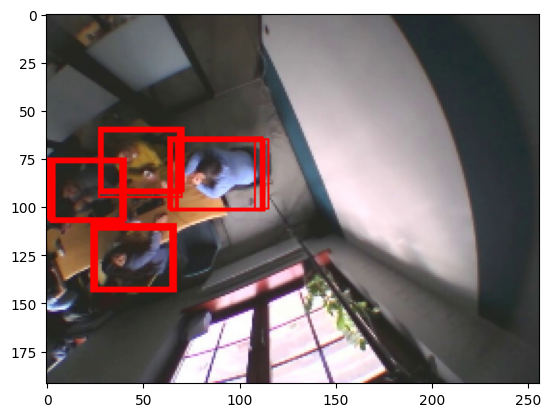

In [17]:
scores = decoded_float_boxes[:, -1] * decoded_float_boxes[:, -2]

boxes = decoded_float_boxes[scores > 0.1][:, :4].copy()
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)

tmp = img.copy()
for box in boxes_xyxy:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)